# 1. 기본 OCR (파인튜닝 전, 베이스 모델)

파인튜닝하기 전 원본 모델(`team-lucid/trocr-small-korean`)로 한글 영수증을 인식하면 어떤지
먼저 보여줍니다. 이 결과가 안 좋아야 다음(파인튜닝한 모델)이랑 비교했을 때 의미가 있습니다.

- 줄 하나짜리 크롭 인식: 이미 잘라놓은 한 줄만 넣어보는 가장 단순한 테스트
- 영수증 전체 인식: EasyOCR로 줄을 검출한 뒤, 검출된 각 줄을 베이스 모델로 인식하는 전체 파이프라인

## 환경 설정

In [9]:
import os

os.environ.setdefault("USE_TF", "0")

import torch
from PIL import Image
from IPython.display import display
from transformers import TrOCRProcessor, VisionEncoderDecoderModel

PROJECT_DIR = os.getcwd()
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

BASE_MODEL_DIR = os.path.join(PROJECT_DIR, "model", "trocr_base")
base_processor = TrOCRProcessor.from_pretrained(BASE_MODEL_DIR)
base_model = VisionEncoderDecoderModel.from_pretrained(BASE_MODEL_DIR).to(DEVICE)
base_model.config.vocab_size = (base_model.config.decoder.vocab_size)
base_model.eval()

print("베이스 모델 로드 완료 (파인튜닝 전)")


Config of the encoder: <class 'transformers.models.deit.modeling_deit.DeiTModel'> is overwritten by shared encoder config: DeiTConfig {
  "attention_probs_dropout_prob": 0.0,
  "encoder_stride": 16,
  "hidden_act": "gelu",
  "hidden_dropout_prob": 0.0,
  "hidden_size": 384,
  "image_size": 384,
  "initializer_range": 0.02,
  "intermediate_size": 1536,
  "layer_norm_eps": 1e-12,
  "model_type": "deit",
  "num_attention_heads": 6,
  "num_channels": 3,
  "num_hidden_layers": 12,
  "patch_size": 16,
  "qkv_bias": true,
  "torch_dtype": "float32",
  "transformers_version": "4.46.3"
}

Config of the decoder: <class 'transformers.models.trocr.modeling_trocr.TrOCRForCausalLM'> is overwritten by shared decoder config: TrOCRConfig {
  "activation_dropout": 0.0,
  "activation_function": "relu",
  "add_cross_attention": true,
  "attention_dropout": 0.0,
  "bos_token_id": 0,
  "classifier_dropout": 0.0,
  "cross_attention_hidden_size": 384,
  "d_model": 256,
  "decoder_attention_heads": 8,
  "decod

베이스 모델 로드 완료 (파인튜닝 전)


## 영수증 줄 하나 인식해보기

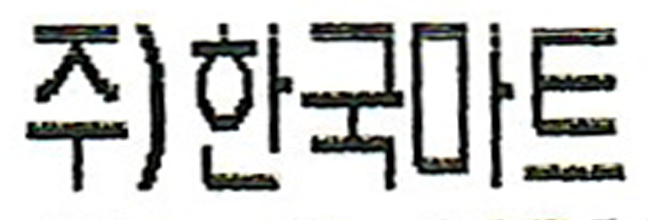

정답        : 주)한국마트
베이스 모델 : 주)한국마트


In [10]:
def base_predict(image, max_length=64):
    if isinstance(image, str):
        image = Image.open(image).convert("RGB")
    pixel_values = base_processor(images=image, return_tensors="pt").pixel_values.to(DEVICE)
    with torch.no_grad():
        generated = base_model.generate(pixel_values, max_length=max_length)
    return base_processor.batch_decode(generated, skip_special_tokens=True)[0]


crop_path = os.path.join(PROJECT_DIR, "samples", "receipt_crop_sample.png")
display(Image.open(crop_path))
print("정답        :", "주)한국마트")
print("베이스 모델 :", base_predict(crop_path))


## 영수증 전체 인식해보기

위에서는 이미 한 줄만 잘라놓은 크롭을 넣었지만, TrOCR은 원래 **한 줄짜리 이미지만 인식**하도록 만들어진
모델이라 영수증 사진 한 장을 통째로 넣으면 결과가 이상하게 나옵니다. 그래서 실제로는:

1. **검출(detection)**: EasyOCR로 사진에서 글자 줄들의 위치(박스)를 찾고
2. **인식(recognition)**: 찾은 박스들을 위→아래 순서로 잘라서 각각 TrOCR(베이스 모델)에 넣어 텍스트로 변환

하는 2단계 파이프라인이 필요합니다.

In [11]:
import re

import easyocr

reader = easyocr.Reader(["ko", "en"], gpu=torch.cuda.is_available())

# 검출 박스가 이 픽셀 크기보다 작으면 노이즈(점, 얼룩 등)일 가능성이 높아 인식을 시도하지 않고 건너뜀
MIN_CROP_WIDTH = 6
MIN_CROP_HEIGHT = 8
# 평균 토큰 확률이 이보다 낮으면 화면에 ⚠️로 표시(오답 확정은 아니고 검수가 필요하다는 신호)
CONF_THRESHOLD = 0.5


def box_rect(box):
    xs = [p[0] for p in box]
    ys = [p[1] for p in box]
    return min(xs), min(ys), max(xs), max(ys)


def sort_reading_order(boxes):
    """위→아래, 같은 줄 안에서는 왼쪽→오른쪽 순으로 정렬."""
    rects = [box_rect(b) for b in boxes]
    order = sorted(range(len(boxes)), key=lambda i: (rects[i][1] + rects[i][3]) / 2)
    heights = [r[3] - r[1] for r in rects]
    avg_h = sum(heights) / len(heights)

    lines, current, current_y = [], [order[0]], (rects[order[0]][1] + rects[order[0]][3]) / 2
    for idx in order[1:]:
        yc = (rects[idx][1] + rects[idx][3]) / 2
        if abs(yc - current_y) < avg_h * 0.6:
            current.append(idx)
        else:
            lines.append(current)
            current = [idx]
            current_y = yc
    lines.append(current)

    result = []
    for line in lines:
        result.extend(sorted(line, key=lambda i: rects[i][0]))
    return [(boxes[i], rects[i]) for i in result]


def normalize_number_spacing(text):
    """'37, 000' -> '37,000' 처럼 천 단위 쉼표 뒤에 낀 어색한 공백만 정리."""
    return re.sub(r"(\d),\s+(?=\d)", r"\1,", text)


def base_predict_image(pil_image, max_length=64):
    """이미 메모리에 있는 PIL 이미지(크롭)를 베이스 모델로 인식.
    텍스트와 함께 생성된 토큰들의 평균 확률(0~1)을 신뢰도로 반환."""
    pixel_values = base_processor(images=pil_image, return_tensors="pt").pixel_values.to(DEVICE)
    with torch.no_grad():
        outputs = base_model.generate(
            pixel_values,
            max_length=max_length,
            output_scores=True,
            return_dict_in_generate=True,
        )
    text = base_processor.batch_decode(outputs.sequences, skip_special_tokens=True)[0]
    text = normalize_number_spacing(text)

    # beam search로 생성된 경우 beam_indices가 있어야 점수가 정확히 계산됨(greedy면 None이라 자동 무시됨)
    transition_scores = base_model.compute_transition_scores(
        outputs.sequences,
        outputs.scores,
        beam_indices=getattr(outputs, "beam_indices", None),
        normalize_logits=True,
    )
    valid_scores = transition_scores[torch.isfinite(transition_scores)]
    confidence = valid_scores.exp().mean().item() if len(valid_scores) else 0.0
    return text, confidence


def format_result(text, confidence):
    if not text.strip():
        return "(인식 실패)"
    return text if confidence >= CONF_THRESHOLD else f"{text} ⚠️"


def ocr_full_receipt(image_path):
    """영수증 사진 한 장 -> (EasyOCR 검출 + 베이스 모델 인식) 결과 줄 리스트.
    ⚠️ 표시는 모델이 스스로 확신하지 못한(평균 토큰 확률이 낮은) 줄이라는 뜻입니다."""
    pil_full = Image.open(image_path).convert("RGB")
    boxes_raw = reader.detect(image_path)[0][0]  # 박스 좌표만 사용, 인식은 우리 모델로
    if not boxes_raw:
        return []

    boxes = [[[x0, y0], [x1, y0], [x1, y1], [x0, y1]] for x0, x1, y0, y1 in boxes_raw]
    ordered = sort_reading_order(boxes)

    lines = []
    for _, rect in ordered:
        x0, y0, x1, y1 = [int(v) for v in rect]
        crop = pil_full.crop((max(0, x0), max(0, y0), x1, y1))
        if crop.width < MIN_CROP_WIDTH or crop.height < MIN_CROP_HEIGHT:
            continue
        text, confidence = base_predict_image(crop)
        lines.append(format_result(text, confidence))
    return lines


print("검출+인식 파이프라인 준비 완료")

Using CPU. Note: This module is much faster with a GPU.


검출+인식 파이프라인 준비 완료


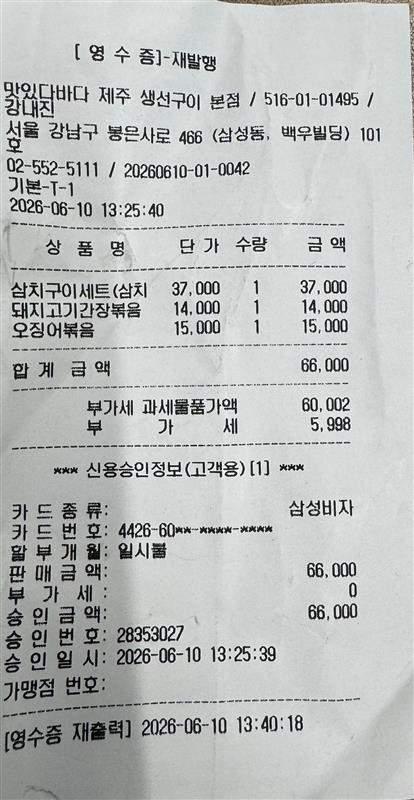

베이스 모델 인식 결과 (image.png):

  [ 영 수
  맑¶담바다
  생선구이 본점
  516-01-01495
  서울 강남구 봉은사로 466 <삼성동, 백우빌딩> 101
  02-552-5111
  20260610-0042
  2026-06-10 13:25:40
  상 품 명
  단 가
  수량 
  금 액
  삼치구이세트 <삼치
  37,000
  37,000
  14,000
  돼지간장볶음
  14,000
  15,000
  15,000
  오징어볶음
  합계 금액
  66,000
  부가세 과세물품가액
  60,002
  5,998
  가
  세
  XM
  신용승인정보《고객용》 [1]
  삼성비자
  4426-60**-**-
  36 홍 ⚠️
  일시
  66,000
  ' ⚠️
  세
  66,000
  (인식 실패)
  28/27-10 13:25:39
  가맹점 번호:
  재출력] 2026-06-10 13:40:18


In [12]:
receipt_path = os.path.join(PROJECT_DIR, "samples", "image.png")

display(Image.open(receipt_path))
print(f"베이스 모델 인식 결과 ({os.path.basename(receipt_path)}):\n")
for line in ocr_full_receipt(receipt_path):
    print(" ", line)